# BIOT 6900 · Module 7 · Parkinson's Disease Knowledge Graph (Neo4j)


In [1]:
# If the kernel restarts after installing, run the cells again from the top.
%pip install neo4j networkx matplotlib pandas requests

Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install python-dotenv neo4j

Note: you may need to restart the kernel to use updated packages.


In [3]:
# Credentials live in a git-ignored .env file next to this notebook:
#   NEO4J_URI=neo4j+s://<id>.databases.neo4j.io
#   NEO4J_USERNAME=<instance id>      (not "neo4j")
#   NEO4J_PASSWORD=<generated password>
# %pip install python-dotenv   # once, if needed
import os
from dotenv import load_dotenv
from neo4j import GraphDatabase


load_dotenv("Neo4j-827b9ec7-Created-2026-10-22.txt")
NEO4J_URI      = os.environ["NEO4J_URI"]
NEO4J_USER     = os.environ["NEO4J_USERNAME"]
NEO4J_PASSWORD = os.environ["NEO4J_PASSWORD"]

driver = GraphDatabase.driver(NEO4J_URI, auth=(NEO4J_USER, NEO4J_PASSWORD))

def run_query(cypher, **params):
    with driver.session() as session:
        return [r.data() for r in session.run(cypher, **params)]

try:
    driver.verify_connectivity(); print("Connected to Neo4j.")
except Exception as e:
    print("Not connected yet — check .env values. Details:", e)


Connected to Neo4j.


## 1 · data  

In [4]:
import pandas as pd
import numpy as np
import networkx as nx
import os
from pathlib import Path

run_query("MATCH (n) DETACH DELETE n")   # start from an empty database every run
run_query("CREATE CONSTRAINT entity_name IF NOT EXISTS "
          "FOR (n:Entity) REQUIRE n.name IS UNIQUE")
...

# ===========================================================================
# Parkinson's disease knowledge graph — data layer
# Genes + evidence come from MY pipeline (Module 2 multi-omics ranking,
# Module 3 druggability re-rank). Other layers were pulled from Open Targets
# (Platform release queried Oct 2026), which re-serves HPO, Reactome and ChEMBL.
# ===========================================================================
DISEASE = "Parkinson's disease"
DATA_DIR = Path("data")
GENOME_WIDE = -np.log10(5e-8)          # 7.30: genome-wide significance threshold

# --- Genes: Module 2 (RNA/protein/GWAS) + Module 3 (druggability) ----------
m2 = pd.read_csv(DATA_DIR / "targets_parkinsons.csv")
m3 = pd.read_csv(DATA_DIR / "targets_parkinsons_w3.csv")
ev = (m2[["rank", "gene", "log2fc_rna", "log2fc_prot", "significant", "neglog10p", "concordant"]]
        .rename(columns={"rank": "m2_rank"})
        .merge(m3[["gene", "p_sm", "p_ab", "rank"]].rename(columns={"rank": "m3_rank"}),
               on="gene", how="inner"))
ev["druggability"]  = ev[["p_sm", "p_ab"]].max(axis=1)
ev["best_modality"] = np.where(ev.p_sm >= ev.p_ab, "small molecule", "antibody")
assert len(ev) == 15, f"expected 15 genes after merge, got {len(ev)}"

# Identifier harmonization: symbol -> Ensembl, resolved with Open Targets mapIds.
# PAM and CHL1 were AMBIGUOUS there (PAM also matched MYCBP2; CHL1 also matched
# DDX11, whose old alias is CHL1); resolved by approved HGNC symbol.
ENSEMBL = {
    "LMNA": "ENSG00000160789", "PBXIP1": "ENSG00000163346", "SNCA": "ENSG00000145335",
    "MAP4K4": "ENSG00000071054", "WDR1": "ENSG00000071127", "KTN1": "ENSG00000126777",
    "BAG3": "ENSG00000151929", "NDUFAF2": "ENSG00000164182", "MAPT": "ENSG00000186868",
    "PAM": "ENSG00000145730", "SH3GL2": "ENSG00000107295", "PPP6R2": "ENSG00000100239",
    "CHL1": "ENSG00000134121", "FYN": "ENSG00000010810", "STK39": "ENSG00000198648",
    "APP": "ENSG00000142192",    # related-disease (context) gene
}
# Open Targets overall association score with Parkinson disease (MONDO_0005180);
# None = no Open Targets association at all.
OT_PD_SCORE = {
    "SNCA": 0.871, "MAPT": 0.678, "STK39": 0.543, "SH3GL2": 0.542, "FYN": 0.452,
    "BAG3": 0.411, "NDUFAF2": 0.368, "MAP4K4": 0.352, "KTN1": 0.150, "LMNA": 0.095,
    "PAM": 0.015, "PPP6R2": 0.013, "CHL1": 0.013, "PBXIP1": None, "WDR1": None,
}

# --- Phenotypes (HPO, as annotated to each disease in Open Targets) --------
HPO = {"Parkinsonism": "HP:0001300", "Bradykinesia": "HP:0002067", "Rigidity": "HP:0002063",
       "Resting tremor": "HP:0002322", "Postural instability": "HP:0002172",
       "Depression": "HP:0000716", "Lewy bodies": "HP:0100315"}
PHENOTYPES = list(HPO)                 # all are annotated to Parkinson disease

# --- Pathways (Reactome, via Open Targets target annotations) ---------------
# Rule: keep every Reactome pathway shared by >=2 genes in this graph, plus up to
# two pathways for genes that share none. STK39, PBXIP1, PAM and PPP6R2 have NO
# Reactome annotation, so they get no pathway edge.
GENE_IN_PATHWAY = {   # (pathway name, Reactome id): genes
    ("Amyloid fiber formation", "R-HSA-977225"):                   ["SNCA", "APP"],
    ("PKR-mediated signaling", "R-HSA-9833482"):                   ["SNCA", "MAPT"],
    ("Deregulated CDK5 neurodegenerative pathways", "R-HSA-8862803"): ["LMNA", "APP"],
    ("Post-translational protein phosphorylation", "R-HSA-8957275"): ["KTN1", "APP"],
    ("Platelet degranulation", "R-HSA-114608"):                    ["WDR1", "APP"],
    ("Lysosome vesicle biogenesis", "R-HSA-432720"):               ["SH3GL2", "APP"],
    ("Clathrin-mediated endocytosis", "R-HSA-8856828"):            ["SH3GL2"],
    ("Complex I biogenesis", "R-HSA-6799198"):                     ["NDUFAF2"],
    ("HSF1-mediated heat shock response", "R-HSA-3371453"):        ["BAG3"],
    ("Oxidative stress induced senescence", "R-HSA-2559580"):      ["MAP4K4"],
    ("Activation of AMPK downstream of NMDARs", "R-HSA-9619483"):  ["MAPT"],
    ("Activated NTRK2 signals through FYN", "R-HSA-9032500"):      ["FYN"],
    ("Reelin signalling pathway", "R-HSA-8866376"):                ["FYN"],
    ("CHL1 interactions", "R-HSA-447041"):                         ["CHL1"],
    ("Nuclear envelope breakdown", "R-HSA-2980766"):               ["LMNA"],
}

# --- Drugs (Open Targets drugAndClinicalCandidates / ChEMBL mechanisms) -----
# (drug, target gene, max clinical stage per Open Targets, mechanism, confidence)
DRUGS = [
    ("Prasinezumab", "SNCA", "PHASE_3", "alpha-synuclein binding antibody", "primary target"),
    ("Cinpanemab",   "SNCA", "PHASE_2", "alpha-synuclein inhibitor antibody", "primary target"),
    ("Gosuranemab",  "MAPT", "PHASE_2", "tau inhibitor antibody", "primary target"),
    ("Tilavonemab",  "MAPT", "PHASE_2", "tau inhibitor antibody", "primary target"),
    ("Bepranemab",   "MAPT", "PHASE_2", "tau inhibitor antibody", "primary target"),
    ("Dasatinib",    "FYN",  "approved (oncology)", "SRC-family kinase inhibitor",
                      "polypharmacology: FYN is 1 of 10 SRC-family targets"),
]

# --- Variants: lead GWAS SNP per gene, from MY Module 2 GWAS Catalog file ---
GWAS_PATH = DATA_DIR / "pd_gwas_associations.tsv"     # TODO: set to your Module 2 file name
VARIANTS = []    # (rsid, gene, pvalue, pubmed)
if GWAS_PATH.exists():
    gw = pd.read_csv(GWAS_PATH, sep="\t", low_memory=False)
    gw["P-VALUE"] = pd.to_numeric(gw["P-VALUE"], errors="coerce")
    for g in ev.gene:
        hit = gw[gw["MAPPED_GENE"].fillna("").str.contains(rf"\b{g}\b", regex=True)]
        if len(hit):
            best = hit.sort_values("P-VALUE").iloc[0]
            VARIANTS.append((str(best["SNPS"]).split(";")[0].strip(), g,
                             float(best["P-VALUE"]), str(best["PUBMEDID"])))
    print(f"lead variants found for {len(VARIANTS)} of {len(ev)} genes")
else:
    print(f"(no GWAS file at {GWAS_PATH}) — variant layer skipped; fix the path")

# --- Related diseases that SHARE phenotypes (power the repurposing query) ---
RELATED = [
    {"name": "Progressive supranuclear palsy", "mondo": "MONDO_0019037",
     "shares": ["Parkinsonism", "Bradykinesia", "Rigidity", "Postural instability"],
     "genes": [("MAPT", 0.827)],                    # (gene, Open Targets score)
     "drugs": []},                                  # anti-tau drugs already on MAPT
    {"name": "Alzheimer's disease", "mondo": "MONDO_0004975",
     "shares": ["Parkinsonism", "Depression"],
     "genes": [("APP", 0.874)],
     "drugs": [("Lecanemab", "APP", "approved", "anti-amyloid-beta antibody", "primary target"),
               ("Donanemab", "APP", "approved", "anti-amyloid-beta antibody", "primary target")]},
]

# --- Patient layer: SYNTHETIC cohort (not real individuals) -----------------
# genotype = number of risk alleles at the SNCA lead SNP (0/1/2)
PATIENTS = [  # (id, age, snca_risk_alleles, prs_percentile, status)
    ("P01", 68, 2, 0.91, "case"), ("P02", 72, 1, 0.74, "case"), ("P03", 65, 0, 0.35, "case"),
    ("P04", 70, 2, 0.83, "case"), ("P05", 61, 0, 0.22, "control"), ("P06", 66, 1, 0.48, "control"),
    ("P07", 74, 1, 0.69, "case"), ("P08", 63, 0, 0.18, "control"), ("P09", 77, 2, 0.88, "case"),
    ("P10", 59, 0, 0.30, "control"), ("P11", 71, 1, 0.57, "control"), ("P12", 69, 0, 0.41, "control"),
]

# ---------------------------------------------------------------------------
# Build nodes/edges. Every edge carries a source and a confidence/evidence value.
# Values are cast to plain Python types (the Neo4j driver rejects numpy ints/bools).
# ---------------------------------------------------------------------------
NODES, EDGES = {}, []
def add_node(n, k, **p): NODES[n] = dict(kind=k, **p)
def add_edge(s, r, d, **p): EDGES.append(dict(src=s, rel=r, dst=d, **p))

add_node(DISEASE, "disease", mondo="MONDO_0005180")
for r in ev.to_dict("records"):
    g = r["gene"]; nlp = float(r["neglog10p"])
    add_node(g, "gene", ensembl=ENSEMBL[g], origin="Part I pipeline",
             gwas_p=float(10 ** -nlp), neglog10p=nlp,
             rna_lfc=float(r["log2fc_rna"]), prot_lfc=float(r["log2fc_prot"]),
             prot_significant=bool(r["significant"]), rna_prot_concordant=bool(r["concordant"]),
             druggability=float(r["druggability"]), best_modality=r["best_modality"],
             ot_pd_score=OT_PD_SCORE[g], m2_rank=int(r["m2_rank"]), m3_rank=int(r["m3_rank"]))
    add_edge(g, "ASSOCIATED_WITH", DISEASE, source="GWAS Catalog (Module 2)",
             pvalue=float(10 ** -nlp), neglog10p=nlp,
             confidence="genome-wide" if nlp >= GENOME_WIDE else "suggestive",
             ot_score=OT_PD_SCORE[g])

for ph in PHENOTYPES:
    add_node(ph, "phenotype", hpo=HPO[ph])
    add_edge(DISEASE, "HAS_PHENOTYPE", ph, source="HPO via Open Targets", confidence="curated annotation")

for rel in RELATED:
    add_node(rel["name"], "disease", mondo=rel["mondo"])
    for ph in rel["shares"]:
        add_edge(rel["name"], "HAS_PHENOTYPE", ph, source="HPO via Open Targets",
                 confidence="curated annotation")
    for g, score in rel["genes"]:
        if g not in NODES:                     # don't overwrite a pipeline gene (MAPT)
            add_node(g, "gene", ensembl=ENSEMBL[g], origin="context (not from Part I pipeline)")
        add_edge(g, "ASSOCIATED_WITH", rel["name"], source="Open Targets association",
                 ot_score=score, confidence="strong" if score >= 0.5 else "moderate")
    DRUGS += rel["drugs"]

for (pw, rid), genes in GENE_IN_PATHWAY.items():
    add_node(pw, "pathway", reactome=rid)
    for g in genes:
        if g in NODES:
            add_edge(g, "PARTICIPATES_IN", pw, source="Reactome via Open Targets", reactome=rid,
                     confidence="curated annotation")

for name, tgt, stage, moa, conf in DRUGS:
    add_node(name, "drug", status=stage, mechanism=moa)
    add_edge(name, "TARGETS", tgt, source="ChEMBL mechanism via Open Targets",
             mechanism=moa, confidence=conf)

for rsid, g, p, pmid in VARIANTS:
    add_node(rsid, "variant")
    add_edge(rsid, "OCCURS_IN", g, source="GWAS Catalog mapped gene (Module 2)",
             pvalue=p, pubmed=pmid, confidence="positional mapping, not causal")

SNCA_LEAD = next((v for v, g, *_ in VARIANTS if g == "SNCA"), None)
for pid, age, n_risk, prs, status in PATIENTS:
    add_node(pid, "patient", age=age, snca_risk_alleles=n_risk, prs_percentile=prs,
             status=status, synthetic=True)
    if SNCA_LEAD and n_risk > 0:
        add_edge(pid, "CARRIES", SNCA_LEAD, source="synthetic cohort", allele_count=n_risk,
                 confidence="synthetic")

print("nodes:", len(NODES), " edges:", len(EDGES))
print("by kind:", pd.Series([d["kind"] for d in NODES.values()]).value_counts().to_dict())
print("edges missing a source:", sum("source" not in e for e in EDGES))


lead variants found for 15 of 15 genes
nodes: 76  edges: 81
by kind: {'gene': 16, 'variant': 15, 'pathway': 15, 'patient': 12, 'drug': 8, 'phenotype': 7, 'disease': 3}
edges missing a source: 0


#### Identifier harmonization check
One node per gene; every edge endpoint resolves; weak edges listed.

In [5]:
# Identifier harmonization check: one node per gene, every edge endpoint exists.
genes = [n for n, d in NODES.items() if d["kind"] == "gene"]
ens = [NODES[g]["ensembl"] for g in genes]
print("gene nodes:", len(genes), "| unique Ensembl ids:", len(set(ens)))
dangling = [e for e in EDGES if e["src"] not in NODES or e["dst"] not in NODES]
print("edges pointing at a missing node:", len(dangling))
print("genes with no pathway edge:",
      sorted(g for g in genes if not any(e["src"] == g and e["rel"] == "PARTICIPATES_IN" for e in EDGES)))
print("sub-genome-wide gene–PD edges:",
      sorted(e["src"] for e in EDGES if e["rel"] == "ASSOCIATED_WITH" and e.get("confidence") == "suggestive"))


gene nodes: 16 | unique Ensembl ids: 16
edges pointing at a missing node: 0
genes with no pathway edge: ['PAM', 'PBXIP1', 'PPP6R2', 'STK39']
sub-genome-wide gene–PD edges: ['CHL1', 'PPP6R2', 'WDR1']


## 2 · Load into Neo4j

In [6]:
run_query("CREATE CONSTRAINT entity_name IF NOT EXISTS "
          "FOR (n:Entity) REQUIRE n.name IS UNIQUE")

KIND_LABEL = {"gene":"Gene","disease":"Disease","phenotype":"Phenotype",
              "pathway":"Pathway","drug":"Drug","variant":"Variant","patient":"Patient"}

for kind, label in KIND_LABEL.items():
    rows = [dict(name=n, **{k: v for k, v in d.items() if k != "kind"})
            for n, d in NODES.items() if d["kind"] == kind]
    if rows:
        run_query(f"UNWIND $rows AS row MERGE (e:{label}:Entity {{name: row.name}}) SET e += row",
                  rows=rows)

from collections import defaultdict
by_rel = defaultdict(list)
for e in EDGES:
    by_rel[e["rel"]].append({"src": e["src"], "dst": e["dst"],
                             "props": {k: v for k, v in e.items() if k not in ("src","dst","rel")}})
for rel, rows in by_rel.items():
    run_query(f"""UNWIND $rows AS row
                  MATCH (a:Entity {{name: row.src}})
                  MATCH (b:Entity {{name: row.dst}})
                  MERGE (a)-[r:{rel}]->(b)
                  SET r += row.props""", rows=rows)

print("node counts:", run_query("MATCH (n) RETURN labels(n)[0] AS label, count(*) AS n ORDER BY n DESC"))
print("relationships:", run_query("MATCH ()-[r]->() RETURN count(r) AS n")[0]["n"])

node counts: [{'label': 'Entity', 'n': 76}]
relationships: 81


## 3 · A quick look

## 4 · Query it — the opening question (Cypher)



In [8]:
# 2 hops: drugs acting on genes associated with your disease
run_query("""
    MATCH (d:Drug)-[:TARGETS]->(g:Gene)-[:ASSOCIATED_WITH]->(dis:Disease)
    WHERE dis.name = $disease
    RETURN d.name AS drug, g.name AS gene, d.status AS status
    ORDER BY drug
""", disease=DISEASE)

[{'drug': 'Bepranemab', 'gene': 'MAPT', 'status': 'PHASE_2'},
 {'drug': 'Cinpanemab', 'gene': 'SNCA', 'status': 'PHASE_2'},
 {'drug': 'Dasatinib', 'gene': 'FYN', 'status': 'approved (oncology)'},
 {'drug': 'Gosuranemab', 'gene': 'MAPT', 'status': 'PHASE_2'},
 {'drug': 'Prasinezumab', 'gene': 'SNCA', 'status': 'PHASE_3'},
 {'drug': 'Tilavonemab', 'gene': 'MAPT', 'status': 'PHASE_2'}]

In [9]:
# 5 hops: drugs on genes of diseases that SHARE A SYMPTOM with your disease
run_query("""
    MATCH (d:Drug)-[:TARGETS]->(g:Gene)-[:ASSOCIATED_WITH]->(other:Disease)
          -[:HAS_PHENOTYPE]->(p:Phenotype)<-[:HAS_PHENOTYPE]-(ad:Disease)
    WHERE ad.name = $disease AND other <> ad
    RETURN d.name AS repurposing_candidate, g.name AS gene,
           other.name AS via_disease, collect(DISTINCT p.name) AS shared_symptoms
    ORDER BY repurposing_candidate
""", disease=DISEASE)

[{'repurposing_candidate': 'Bepranemab',
  'gene': 'MAPT',
  'via_disease': 'Progressive supranuclear palsy',
  'shared_symptoms': ['Parkinsonism',
   'Bradykinesia',
   'Rigidity',
   'Postural instability']},
 {'repurposing_candidate': 'Donanemab',
  'gene': 'APP',
  'via_disease': "Alzheimer's disease",
  'shared_symptoms': ['Parkinsonism', 'Depression']},
 {'repurposing_candidate': 'Gosuranemab',
  'gene': 'MAPT',
  'via_disease': 'Progressive supranuclear palsy',
  'shared_symptoms': ['Parkinsonism',
   'Bradykinesia',
   'Rigidity',
   'Postural instability']},
 {'repurposing_candidate': 'Lecanemab',
  'gene': 'APP',
  'via_disease': "Alzheimer's disease",
  'shared_symptoms': ['Parkinsonism', 'Depression']},
 {'repurposing_candidate': 'Tilavonemab',
  'gene': 'MAPT',
  'via_disease': 'Progressive supranuclear palsy',
  'shared_symptoms': ['Parkinsonism',
   'Bradykinesia',
   'Rigidity',
   'Postural instability']}]

#### One full path (for the report)

In [10]:
# One full repurposing path, node by node, so a reader can follow the reasoning.
for row in run_query("""
    MATCH path = (d:Drug)-[:TARGETS]->(g:Gene)-[:ASSOCIATED_WITH]->(other:Disease)
                 -[:HAS_PHENOTYPE]->(p:Phenotype)<-[:HAS_PHENOTYPE]-(pd:Disease {name: $disease})
    WHERE other <> pd
    RETURN [n IN nodes(path) | n.name] AS nodes,
           [r IN relationships(path) | type(r)] AS rels
    LIMIT 4
""", disease=DISEASE):
    n, r = row["nodes"], row["rels"]
    print(f"({n[0]})-[{r[0]}]->({n[1]})-[{r[1]}]->({n[2]})-[{r[2]}]->({n[3]})<-[{r[3]}]-({n[4]})")


(Gosuranemab)-[TARGETS]->(MAPT)-[ASSOCIATED_WITH]->(Progressive supranuclear palsy)-[HAS_PHENOTYPE]->(Parkinsonism)<-[HAS_PHENOTYPE]-(Parkinson's disease)
(Tilavonemab)-[TARGETS]->(MAPT)-[ASSOCIATED_WITH]->(Progressive supranuclear palsy)-[HAS_PHENOTYPE]->(Parkinsonism)<-[HAS_PHENOTYPE]-(Parkinson's disease)
(Bepranemab)-[TARGETS]->(MAPT)-[ASSOCIATED_WITH]->(Progressive supranuclear palsy)-[HAS_PHENOTYPE]->(Parkinsonism)<-[HAS_PHENOTYPE]-(Parkinson's disease)
(Lecanemab)-[TARGETS]->(APP)-[ASSOCIATED_WITH]->(Alzheimer's disease)-[HAS_PHENOTYPE]->(Parkinsonism)<-[HAS_PHENOTYPE]-(Parkinson's disease)


#### Stricter evidence bar

In [11]:
# "An edge is evidence, not truth": re-ask the 2-hop question using only
# genome-wide-significant gene–PD edges, and compare with the result above.
run_query("""
    MATCH (d:Drug)-[t:TARGETS]->(g:Gene)-[a:ASSOCIATED_WITH]->(dis:Disease {name: $disease})
    WHERE a.confidence = 'genome-wide'
    RETURN d.name AS drug, g.name AS gene, a.neglog10p AS neglog10p, t.confidence AS target_confidence
    ORDER BY gene, drug
""", disease=DISEASE)


[{'drug': 'Dasatinib',
  'gene': 'FYN',
  'neglog10p': 14.397940008672036,
  'target_confidence': 'polypharmacology: FYN is 1 of 10 SRC-family targets'},
 {'drug': 'Bepranemab',
  'gene': 'MAPT',
  'neglog10p': 68.0,
  'target_confidence': 'primary target'},
 {'drug': 'Gosuranemab',
  'gene': 'MAPT',
  'neglog10p': 68.0,
  'target_confidence': 'primary target'},
 {'drug': 'Tilavonemab',
  'gene': 'MAPT',
  'neglog10p': 68.0,
  'target_confidence': 'primary target'},
 {'drug': 'Cinpanemab',
  'gene': 'SNCA',
  'neglog10p': 169.39794000867204,
  'target_confidence': 'primary target'},
 {'drug': 'Prasinezumab',
  'gene': 'SNCA',
  'neglog10p': 169.39794000867204,
  'target_confidence': 'primary target'}]

## 5 · Biomarker prioritization (centrality)

Provided. PageRank fused with your gene evidence.

> **TODO (report):** which genes rank highest? Does that match the biology you
> expect for your disease? Flag any non-obvious hit.

In [12]:
# PageRank in NetworkX, fused with the gene evidence (runs on any Neo4j tier).
G = nx.DiGraph()
for name, d in NODES.items():
    G.add_node(name, **d)
for e in EDGES:
    G.add_edge(e["src"], e["dst"], **{k: v for k, v in e.items() if k not in ("src", "dst")})

pr = nx.pagerank(G)
rows = [{"gene": n, "pagerank": round(pr[n], 4), "neglog10p": d.get("neglog10p"),
         "druggability": d.get("druggability"), "ot_pd_score": d.get("ot_pd_score"),
         "degree": G.degree(n), "origin": d.get("origin")}
        for n, d in G.nodes(data=True) if d["kind"] == "gene"]
biomarkers = pd.DataFrame(rows)

# Fusion: mean percentile rank across PageRank, GWAS strength and druggability
# (pipeline genes only; APP is a context gene with no Part I evidence).
pipe = biomarkers["origin"] == "Part I pipeline"
for col in ["pagerank", "neglog10p", "druggability"]:
    biomarkers.loc[pipe, col + "_pct"] = biomarkers.loc[pipe, col].rank(pct=True)
biomarkers["fused_score"] = biomarkers[["pagerank_pct", "neglog10p_pct", "druggability_pct"]].mean(axis=1).round(3)
biomarkers = biomarkers.sort_values(["fused_score", "pagerank"], ascending=False)
print("Candidate biomarkers for", DISEASE, "(PageRank + evidence):")
print(biomarkers.drop(columns=[c for c in biomarkers if c.endswith("_pct")]).to_string(index=False))
biomarkers.to_csv("biomarker_ranking.csv", index=False)


Candidate biomarkers for Parkinson's disease (PageRank + evidence):
   gene  pagerank  neglog10p  druggability  ot_pd_score  degree                             origin  fused_score
    FYN    0.0170  14.397940      0.960006        0.452       5                    Part I pipeline        0.822
   SNCA    0.0543 169.397940      0.023355        0.871       6                    Part I pipeline        0.778
  STK39    0.0117  41.397940      0.924576        0.543       2                    Part I pipeline        0.744
   MAPT    0.0278  68.000000      0.006897        0.678       8                    Part I pipeline        0.667
 PBXIP1    0.0117  38.698970      0.037078          NaN       2                    Part I pipeline        0.589
 MAP4K4    0.0117  12.096910      0.665151        0.352       3                    Part I pipeline        0.589
 SH3GL2    0.0117  20.096910      0.071591        0.542       4                    Part I pipeline        0.589
NDUFAF2    0.0117  14.301030      0.

## 6 · Communities

Provided. Modularity clustering groups densely connected nodes.

> **TODO (report):** pick ONE community and read it as a subtype or mechanism
> hypothesis.

In [13]:
from networkx.algorithms.community import greedy_modularity_communities
comms = greedy_modularity_communities(G.to_undirected())
print(f"{len(comms)} communities:")
for i, c in enumerate(comms):
    print(f"  {i}: {sorted(c)}")


16 communities:
  0: ["Alzheimer's disease", 'Bradykinesia', 'Depression', 'Lewy bodies', 'PAM', 'PBXIP1', 'PPP6R2', "Parkinson's disease", 'Parkinsonism', 'Postural instability', 'Progressive supranuclear palsy', 'Resting tremor', 'Rigidity', 'STK39', 'rs10775809', 'rs116114495', 'rs12987123', 'rs26431']
  1: ['Activation of AMPK downstream of NMDARs', 'Amyloid fiber formation', 'Bepranemab', 'Cinpanemab', 'Gosuranemab', 'MAPT', 'PKR-mediated signaling', 'Prasinezumab', 'SNCA', 'Tilavonemab', 'rs17649553']
  2: ['APP', 'Donanemab', 'KTN1', 'Lecanemab', 'Platelet degranulation', 'Post-translational protein phosphorylation', 'WDR1', 'rs10939702', 'rs8012377']
  3: ['P01', 'P02', 'P04', 'P06', 'P07', 'P09', 'P11', 'rs356182']
  4: ['Activated NTRK2 signals through FYN', 'Dasatinib', 'FYN', 'Reelin signalling pathway', 'rs9487736']
  5: ['Deregulated CDK5 neurodegenerative pathways', 'LMNA', 'Nuclear envelope breakdown', 'rs513043']
  6: ['Clathrin-mediated endocytosis', 'Lysosome vesicle

#### Patient stratification (synthetic cohort)

In [14]:
# Patient stratification (SYNTHETIC cohort) by risk-allele count at the SNCA lead SNP
run_query("""
    MATCH (p:Patient)
    RETURN p.snca_risk_alleles AS snca_risk_alleles, count(*) AS n,
           sum(CASE WHEN p.status = 'case' THEN 1 ELSE 0 END) AS cases,
           round(avg(p.prs_percentile), 2) AS mean_prs
    ORDER BY snca_risk_alleles DESC
""")


[{'snca_risk_alleles': 2, 'n': 3, 'cases': 3, 'mean_prs': 0.87},
 {'snca_risk_alleles': 1, 'n': 4, 'cases': 2, 'mean_prs': 0.62},
 {'snca_risk_alleles': 0, 'n': 5, 'cases': 1, 'mean_prs': 0.29}]

## 7 · Visualize and export

Provided. Draws your graph coloured by kind and exports your node/edge table.
Both the figure and the CSV are graded artifacts — commit them.

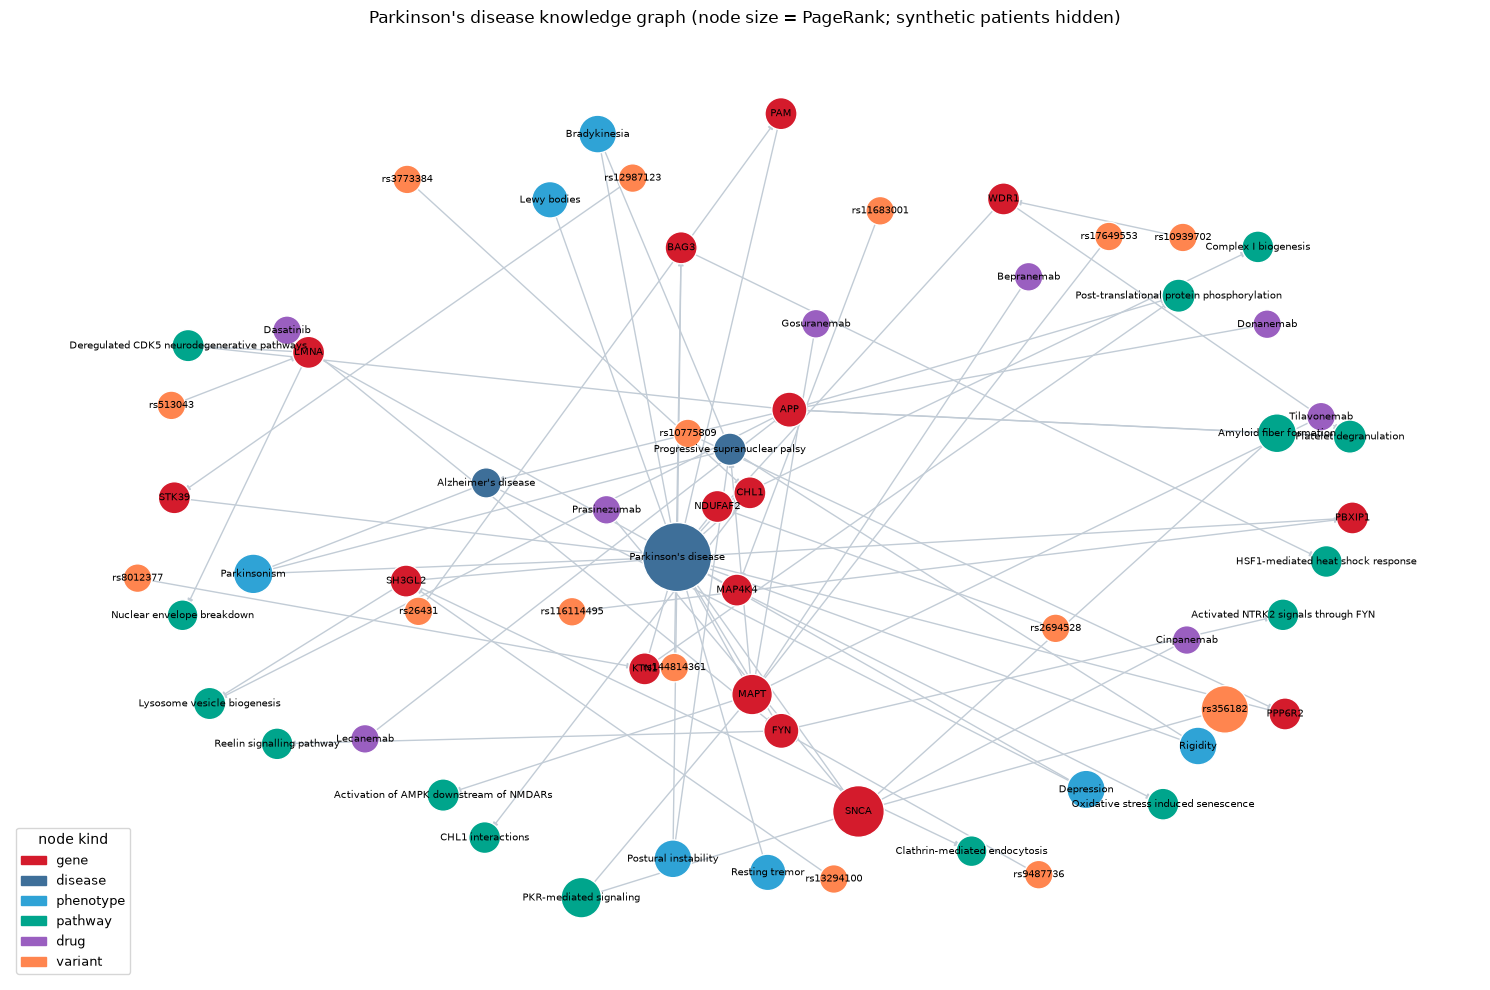

saved my_knowledge_graph.png, nodes.csv, edges.csv


In [15]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

KIND_COLOR = {"gene":"#D41B2C","disease":"#3E6F99","phenotype":"#2FA3D6",
              "pathway":"#00A58C","drug":"#9A5FC0","variant":"#FF854F","patient":"#8A94A3"}
H = G.subgraph([n for n, d in G.nodes(data=True) if d["kind"] != "patient"])
pos = nx.spring_layout(H, seed=7, k=0.9)
plt.figure(figsize=(15, 10))
nx.draw_networkx_edges(H, pos, edge_color="#C2CCD6", width=1.0, arrows=True, arrowsize=8)
nx.draw_networkx_nodes(H, pos, node_size=[300 + 20000 * pr[n] for n in H.nodes()],
                       node_color=[KIND_COLOR[H.nodes[n]["kind"]] for n in H.nodes()],
                       edgecolors="white")
nx.draw_networkx_labels(H, pos, font_size=7)
plt.legend(handles=[Patch(color=c, label=k) for k, c in KIND_COLOR.items() if k != "patient"],
           loc="lower left", fontsize=9, title="node kind")
plt.axis("off")
plt.title(f"{DISEASE} knowledge graph (node size = PageRank; synthetic patients hidden)")
plt.tight_layout()
plt.savefig("my_knowledge_graph.png", dpi=150, bbox_inches="tight")   # <- commit this
plt.show()

pd.DataFrame([dict(name=n, **d) for n, d in NODES.items()]).to_csv("nodes.csv", index=False)
pd.DataFrame(EDGES).to_csv("edges.csv", index=False)
print("saved my_knowledge_graph.png, nodes.csv, edges.csv")


## 8 · Your report (the 40%)

Write a **3–4 page report** answering these four, in your own words:

1. **Schema and evidence** — why these node and edge types, and what evidence you put on the edges.
2. **Top targets** — which genes rank highest by centrality (§5), and does that match the biology you expect? Any non-obvious hit?
3. **A hypothesis from a path** — one repurposing or shared-mechanism hypothesis a path in your graph suggests (§4), and what would test it.
4. **Limitations** — an edge is evidence, not truth. Which of your edges are weak, and how would the answer change with better data? Note where you used (or would use) AI to harmonize data or write queries, and how you checked it.

#### Submit
- This notebook (**Kernel → Restart & Run All** first; credentials in a git-ignored file, not committed).
- `my_knowledge_graph.png`, `nodes.csv`, `edges.csv`.
- Your 3–4 page report (PDF) and a short README (name + your disease).
- Push to your biot6900 repo and post the link on Canvas.

#### Reset (to start over)
```cypher
MATCH (n) DETACH DELETE n      // wipes the database — run deliberately
```
